# Practical Session 5: Feature Selection: Filter and Wrapper Methods

## Student: Kaddour Abdelmalek Islam (AII2 — 2nd Cycle 2nd Year Engineering Degree)

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — 569 samples, 30 continuous features.  
All experiments use `random_state=42` and a fixed 70/30 stratified train/test split.


In [1]:
import time
import math
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    f_classif,
    mutual_info_classif,
    SequentialFeatureSelector,
    RFE,
    RFECV
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

RANDOM_STATE = 42


---
## Part A. Data Inspection and Baseline
### A.1 Initial Inspection


In [2]:
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame
X = cancer.data
y = cancer.target
feature_names = cancer.feature_names.tolist()

print(f"Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
df.describe().T[['mean', 'std', 'min', 'max']].head(10)


Dimensions: 569 rows x 31 columns
Missing values: 0
Duplicate rows: 0


,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.11000
mean texture,19.289649,4.301036,9.71000,39.28000
mean perimeter,91.969033,24.298981,43.79000,188.50000
mean area,654.889104,351.914129,143.50000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.16340
mean compactness,0.104341,0.052813,0.01938,0.34540
mean concavity,0.088799,0.079720,0.00000,0.42680
mean concave points,0.048919,0.038803,0.00000,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.09744


### A.2 Target Distribution and Dummy Baseline

Target counts:
target
Benign (1)       357
Malignant (0)    212
Name: count, dtype: int64


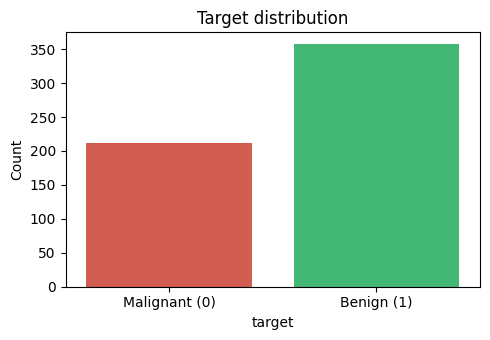

DummyClassifier baseline accuracy: 0.6274


In [3]:
print("Target counts:")
print(y.value_counts().rename({0: 'Malignant (0)', 1: 'Benign (1)'}))

plt.figure(figsize=(5, 3.5))
sns.countplot(x=y, palette=['#e74c3c', '#2ecc71'])
plt.title("Target distribution")
plt.xticks([0, 1], ['Malignant (0)', 'Benign (1)'])
plt.ylabel("Count")
plt.tight_layout()
plt.show()

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X, y)
print(f"DummyClassifier baseline accuracy: {dummy.score(X, y):.4f}")


### A.3 Train/Test Split & Baseline Model

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe_baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

t0 = time.perf_counter()
pipe_baseline.fit(X_train, y_train)
t_base = time.perf_counter() - t0

y_tr_pred = pipe_baseline.predict(X_train)
y_te_pred = pipe_baseline.predict(X_test)

pd.DataFrame([{
    'Model': 'Baseline LogisticRegression (All 30 features)',
    'Nb features': 30,
    'Train Accuracy': accuracy_score(y_train, y_tr_pred),
    'Test Accuracy': accuracy_score(y_test, y_te_pred),
    'Train F1': f1_score(y_train, y_tr_pred),
    'Test F1': f1_score(y_test, y_te_pred),
    'Time (s)': t_base
}])


,Model,Nb features,Train Accuracy,Test Accuracy,Train F1,Test F1,Time (s)
0,Baseline LogisticRegression (All 30 features),30,0.987437,0.988304,0.99006,0.990654,0.017754


### A.4 Correlation Matrix and Redundant Features

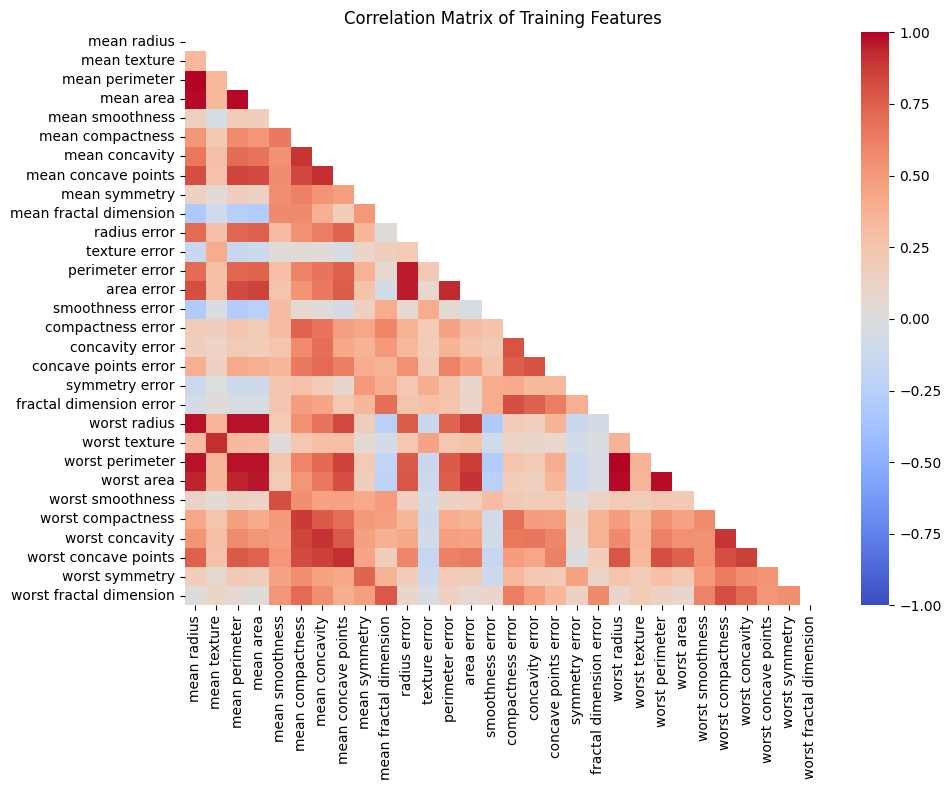

,Feature 1,Feature 2,Correlation
0,mean radius,mean perimeter,0.998
1,mean radius,mean area,0.991
2,mean radius,worst radius,0.974
3,mean radius,worst perimeter,0.970
4,mean radius,worst area,0.945
5,mean texture,worst texture,0.917
6,mean perimeter,mean area,0.989
7,mean perimeter,worst radius,0.974
8,mean perimeter,worst perimeter,0.975
9,mean perimeter,worst area,0.944


In [5]:
plt.figure(figsize=(10, 8))
corr_train = X_train.corr()
mask = np.triu(np.ones_like(corr_train, dtype=bool))
sns.heatmap(corr_train, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix of Training Features")
plt.tight_layout()
plt.show()

redundant = []
for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):
        r = corr_train.iloc[i, j]
        if abs(r) >= 0.90:
            redundant.append((feature_names[i], feature_names[j], round(r, 3)))

pd.DataFrame(redundant, columns=['Feature 1', 'Feature 2', 'Correlation']).head(10)


**Why this dataset is a good candidate for feature selection:**
- **High geometric collinearity:** Several features measure the same physical properties of cell nuclei (e.g. radius, perimeter, and area with $r > 0.98$).
- **Reduces model complexity and cost:** Eliminating redundant measurements reduces data collection and segmentation effort while preventing overfitting without degrading accuracy.


---
## Part B. Filter Methods
### B.1 Variance Threshold


In [6]:
variances = X_train.var(ddof=0)
vt_table = []
for th in [0, 0.01, 0.1]:
    vt = VarianceThreshold(threshold=th)
    vt.fit(X_train)
    removed = sum(~vt.get_support())
    kept = sum(vt.get_support())
    vt_table.append({'Threshold': th, 'Removed features': removed, 'Remaining features': kept})

pd.DataFrame(vt_table)


,Threshold,Removed features,Remaining features
0,0.00,0,30
1,0.01,16,14
2,0.10,19,11


**Comment on Variance Threshold:**
- Applying this filter after standardization is meaningless because all standardized features have variance equal to 1 ($	ext{Var}(Z)=1$).
- On this dataset, a variance threshold is of limited use because variance depends directly on measurement scales. Small-magnitude variables (like `smoothness error` $pprox 10^{-5}$) are dropped regardless of their predictive relevance.


### B.2 Removing Correlated Features

In [7]:
def remove_correlated(X, threshold):
    corr_matrix = X.corr().abs()
    y_corrs = X.apply(lambda col: abs(np.corrcoef(col, y_train)[0, 1]))
    to_drop = set()
    cols = list(X.columns)
    for i in range(len(cols)):
        col_i = cols[i]
        if col_i in to_drop:
            continue
        for j in range(i + 1, len(cols)):
            col_j = cols[j]
            if col_j in to_drop:
                continue
            if corr_matrix.loc[col_i, col_j] > threshold:
                if y_corrs[col_i] >= y_corrs[col_j]:
                    to_drop.add(col_j)
                else:
                    to_drop.add(col_i)
                    break
    return [c for c in cols if c not in to_drop]

corr_table = []
for th in [0.95, 0.90, 0.80]:
    kept = remove_correlated(X_train, th)
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])
    pipe.fit(X_train[kept], y_train)
    acc = pipe.score(X_test[kept], y_test)
    corr_table.append({'Threshold': th, 'Remaining features': len(kept), 'Test Accuracy': acc})

pd.DataFrame(corr_table)


,Threshold,Remaining features,Test Accuracy
0,0.95,23,0.982456
1,0.90,19,0.970760
2,0.80,13,0.941520


**Is removing redundancy enough to improve accuracy?**  
No. As the correlation threshold is tightened from 0.95 (23 features, acc = 0.9825) to 0.80 (13 features, acc = 0.9415), test accuracy slightly drops compared to the baseline (0.9883). Regularized logistic regression naturally accommodates correlated features, and aggressively dropping them discards useful complementary signals.


### B.3 Univariate Scores and SelectKBest

Spearman rank correlation between F-score and Mutual Info: 0.9657


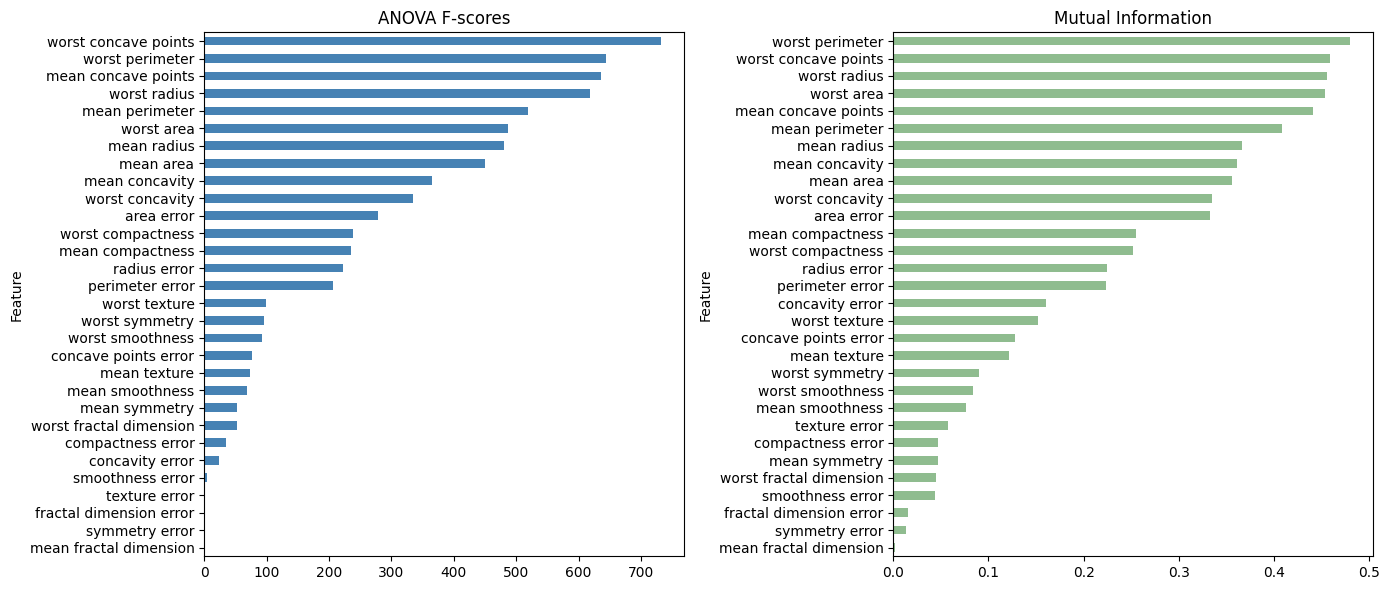

In [8]:
f_scores, f_pvalues = f_classif(X_train, y_train)
mi_scores = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)

df_scores = pd.DataFrame({
    'Feature': feature_names,
    'F_Score': f_scores,
    'Mutual_Info': mi_scores
})

rho, _ = spearmanr(df_scores['F_Score'], df_scores['Mutual_Info'])
print(f"Spearman rank correlation between F-score and Mutual Info: {rho:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
df_scores.sort_values('F_Score').plot.barh(x='Feature', y='F_Score', ax=axes[0], color='steelblue', legend=False)
axes[0].set_title("ANOVA F-scores")
df_scores.sort_values('Mutual_Info').plot.barh(x='Feature', y='Mutual_Info', ax=axes[1], color='darkseagreen', legend=False)
axes[1].set_title("Mutual Information")
plt.tight_layout()
plt.show()


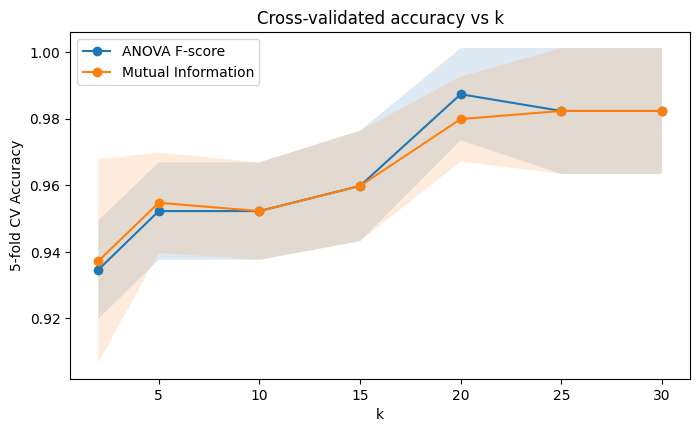

ANOVA F-score: Best k = 20 (Mean=0.9874), Smallest k within 1-std = 20
Mutual Information: Best k = 25 (Mean=0.9824), Smallest k within 1-std = 20


In [9]:
k_list = [2, 5, 10, 15, 20, 25, 30]
k_results = []

for name, score_func in [('ANOVA F-score', f_classif), 
                         ('Mutual Information', lambda X, y: mutual_info_classif(X, y, random_state=RANDOM_STATE))]:
    means, stds = [], []
    for k in k_list:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('sel', SelectKBest(score_func, k=k)),
            ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        ])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
        means.append(scores.mean())
        stds.append(scores.std())
        k_results.append({'Score': name, 'k': k, 'CV_Mean': scores.mean(), 'CV_Std': scores.std()})

df_k = pd.DataFrame(k_results)

plt.figure(figsize=(8, 4.5))
for name, grp in df_k.groupby('Score'):
    plt.plot(grp['k'], grp['CV_Mean'], marker='o', label=name)
    plt.fill_between(grp['k'], grp['CV_Mean'] - grp['CV_Std'], grp['CV_Mean'] + grp['CV_Std'], alpha=0.15)
plt.xlabel("k")
plt.ylabel("5-fold CV Accuracy")
plt.title("Cross-validated accuracy vs k")
plt.legend()
plt.show()

# 1-std rule
for name, grp in df_k.groupby('Score'):
    best_row = grp.loc[grp['CV_Mean'].idxmax()]
    cutoff = best_row['CV_Mean'] - best_row['CV_Std']
    k_star = grp[grp['CV_Mean'] >= cutoff]['k'].min()
    print(f"{name}: Best k = {int(best_row['k'])} (Mean={best_row['CV_Mean']:.4f}), Smallest k within 1-std = {k_star}")


**Why univariate filters select several nearly identical features:**  
Univariate filters evaluate each feature independently against the target. Features like `worst perimeter`, `worst radius`, and `worst area` each have high individual correlation with cancer diagnosis, so they all receive high scores and are picked together without the filter recognizing their mutual redundancy.


---
## Part C. Wrapper Methods
### C.1 Forward Selection


Scikit-learn SFS features: ['mean radius', 'mean texture', 'mean perimeter', 'mean compactness', 'texture error', 'smoothness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness']
Custom Forward features:   ['worst radius', 'worst smoothness', 'worst texture', 'mean radius', 'mean texture', 'worst perimeter', 'texture error', 'mean perimeter', 'mean compactness', 'smoothness error']
Overlap: 10/10


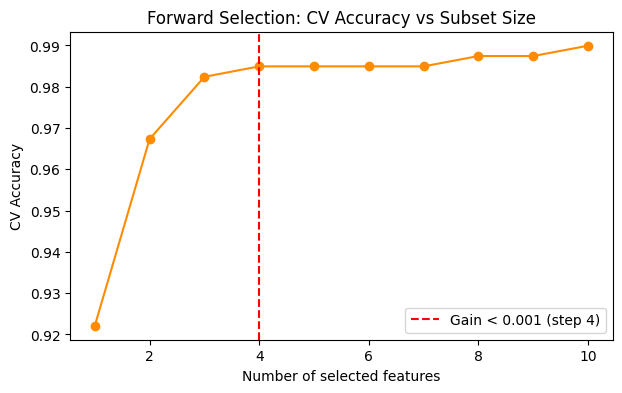

In [10]:
scaler = StandardScaler()
X_tr_s = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_names, index=X_train.index)
X_te_s = pd.DataFrame(scaler.transform(X_test), columns=feature_names, index=X_test.index)

# 1. Scikit-learn SFS forward
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
sfs_fwd = SequentialFeatureSelector(lr, n_features_to_select=10, direction="forward", scoring="accuracy", cv=cv, n_jobs=-1)
sfs_fwd.fit(X_tr_s, y_train)
sklearn_fwd_feats = list(X_train.columns[sfs_fwd.get_support()])

# 2. Custom Forward Selection
def forward_selection(X, y, max_features=10, tol=0.001, cv=cv):
    selected = []
    remaining = list(X.columns)
    history = []
    prev_score = 0.0
    for step in range(1, max_features + 1):
        best_score = -1.0
        best_feat = None
        for col in remaining:
            trial = selected + [col]
            score = cross_val_score(lr, X[trial], y, cv=cv, scoring="accuracy").mean()
            if score > best_score:
                best_score = score
                best_feat = col
        gain = best_score - prev_score if step > 1 else best_score
        selected.append(best_feat)
        remaining.remove(best_feat)
        history.append({'k': step, 'Added': best_feat, 'CV_Accuracy': best_score, 'Gain': gain})
        prev_score = best_score
    return selected, pd.DataFrame(history)

custom_fwd_feats, fwd_hist = forward_selection(X_tr_s, y_train, max_features=10)

print("Scikit-learn SFS features:", sklearn_fwd_feats)
print("Custom Forward features:  ", custom_fwd_feats)
print(f"Overlap: {len(set(sklearn_fwd_feats).intersection(set(custom_fwd_feats)))}/10")

plt.figure(figsize=(7, 4))
plt.plot(fwd_hist['k'], fwd_hist['CV_Accuracy'], marker='o', color='darkorange')
plt.axvline(x=4, color='red', linestyle='--', label='Gain < 0.001 (step 4)')
plt.xlabel("Number of selected features")
plt.ylabel("CV Accuracy")
plt.title("Forward Selection: CV Accuracy vs Subset Size")
plt.legend()
plt.show()


### C.2 Backward Elimination

Scikit-learn Backward features: ['area error', 'fractal dimension error', 'smoothness error', 'texture error', 'worst concavity', 'worst perimeter', 'worst radius', 'worst smoothness', 'worst symmetry', 'worst texture']
Custom Backward features:       ['area error', 'fractal dimension error', 'smoothness error', 'texture error', 'worst concavity', 'worst perimeter', 'worst radius', 'worst smoothness', 'worst symmetry', 'worst texture']


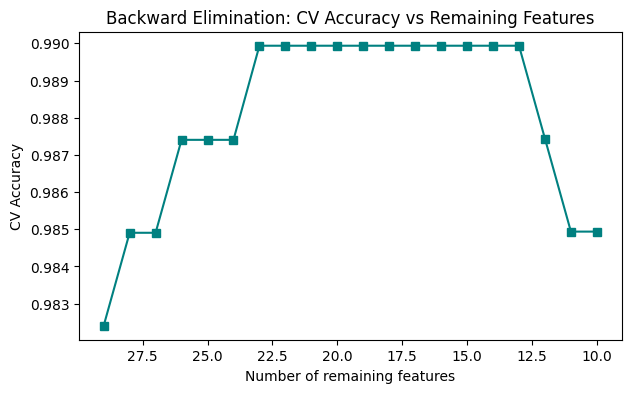

In [11]:
# 1. Scikit-learn SFS backward
sfs_bwd = SequentialFeatureSelector(lr, n_features_to_select=10, direction="backward", scoring="accuracy", cv=cv, n_jobs=-1)
sfs_bwd.fit(X_tr_s, y_train)
sklearn_bwd_feats = list(X_train.columns[sfs_bwd.get_support()])

# 2. Custom Backward Elimination
def backward_elimination(X, y, n_features_to_select=10, cv=cv):
    current = list(X.columns)
    history = []
    while len(current) > n_features_to_select:
        best_score = -1.0
        worst_feat = None
        for col in current:
            trial = [f for f in current if f != col]
            score = cross_val_score(lr, X[trial], y, cv=cv, scoring="accuracy").mean()
            if score > best_score:
                best_score = score
                worst_feat = col
        current.remove(worst_feat)
        history.append({'Remaining': len(current), 'Removed': worst_feat, 'CV_Accuracy': best_score})
    return current, pd.DataFrame(history)

custom_bwd_feats, bwd_hist = backward_elimination(X_tr_s, y_train, n_features_to_select=10)

print("Scikit-learn Backward features:", sorted(sklearn_bwd_feats))
print("Custom Backward features:      ", sorted(custom_bwd_feats))

plt.figure(figsize=(7, 4))
plt.plot(bwd_hist['Remaining'], bwd_hist['CV_Accuracy'], marker='s', color='teal')
plt.xlabel("Number of remaining features")
plt.ylabel("CV Accuracy")
plt.title("Backward Elimination: CV Accuracy vs Remaining Features")
plt.gca().invert_xaxis()
plt.show()


**Why Forward Selection and Backward Elimination features are not identical:**  
Forward Selection and Backward Elimination are greedy and path-dependent. Forward Selection starts empty and can never remove an early feature that becomes redundant later. Backward Elimination starts with the full feature set and evaluates features in a joint context. They explore different search trajectories and end up at different local optima.


### C.3 Recursive Feature Elimination (RFE & RFECV)

,Feature,Selected,Ranking
3,mean area,True,1
7,mean concave points,True,1
13,area error,True,1
27,worst concave points,True,1
20,worst radius,True,1
21,worst texture,True,1
22,worst perimeter,True,1
23,worst area,True,1
28,worst symmetry,True,1
24,worst smoothness,True,1


RFECV optimal number of features: 8


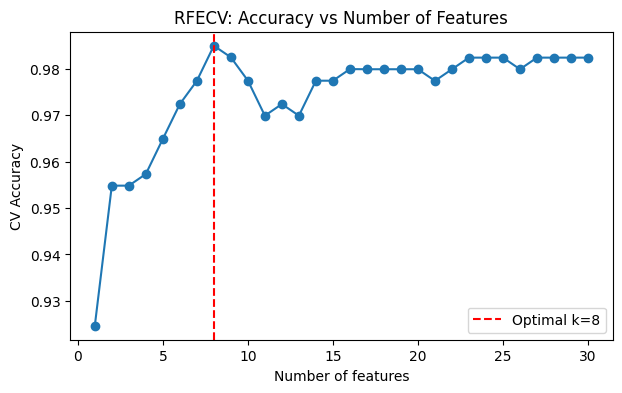

Overlap LR and Linear SVC: 8/10
Overlap LR and RandomForest: 6/10


In [12]:
# 1. RFE with Logistic Regression
rfe_lr = RFE(lr, n_features_to_select=10).fit(X_tr_s, y_train)
rfe_df = pd.DataFrame({'Feature': feature_names, 'Selected': rfe_lr.support_, 'Ranking': rfe_lr.ranking_})
display(rfe_df.sort_values('Ranking').head(10))

# 2. RFECV
rfecv = RFECV(lr, step=1, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_tr_s, y_train)
print(f"RFECV optimal number of features: {rfecv.n_features_}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, 31), rfecv.cv_results_['mean_test_score'], marker='o')
plt.axvline(x=rfecv.n_features_, color='red', linestyle='--', label=f'Optimal k={rfecv.n_features_}')
plt.xlabel("Number of features")
plt.ylabel("CV Accuracy")
plt.title("RFECV: Accuracy vs Number of Features")
plt.legend()
plt.show()

# 3. RFE with RandomForest and Linear SVC
rfe_rf = RFE(RandomForestClassifier(random_state=RANDOM_STATE), n_features_to_select=10).fit(X_tr_s, y_train)
rfe_svc = RFE(SVC(kernel='linear', random_state=RANDOM_STATE), n_features_to_select=10).fit(X_tr_s, y_train)

feats_lr = set(X.columns[rfe_lr.support_])
feats_rf = set(X.columns[rfe_rf.support_])
feats_svc = set(X.columns[rfe_svc.support_])

print(f"Overlap LR and Linear SVC: {len(feats_lr.intersection(feats_svc))}/10")
print(f"Overlap LR and RandomForest: {len(feats_lr.intersection(feats_rf))}/10")


**RFE with different estimators & comparison with Backward Elimination:**
- **Estimator differences:** Linear SVC and Logistic Regression share 8/10 features because both are linear margin-based classifiers using coefficient weights ($|eta_j|$). Random Forest shares only 6/10 because its split criterion (Gini impurity) selects non-linear thresholds on morphological size and shape (`mean area`, `worst concavity`).
- **Difference between RFE and Backward Elimination:**
  - *Criterion:* Backward Elimination retrains CV models for each feature removal to evaluate actual CV accuracy. RFE uses the internal coefficients of a single model fit to prune features without retraining every combination.
  - *Number of models:* Backward Elimination trains $5 	imes \sum_{i=0}^{19}(30-i) = 2,050$ models. RFE trains only 20 models ($O(p)$).


### C.4 Cost of the Wrapper Search

In [13]:
k_target = 10
p = 30
K_folds = 5

models_fwd = K_folds * sum(p - i for i in range(k_target))
models_bwd = K_folds * sum(p - i for i in range(p - k_target))
models_exhaustive = K_folds * sum(math.comb(p, k) for k in range(1, k_target + 1))

print(f"Models trained by Forward Selection (k=10): {models_fwd}")
print(f"Models trained by Backward Elimination (30->10): {models_bwd}")
print(f"Models trained by Exhaustive Search (subsets <= 10): {models_exhaustive:,}")


Models trained by Forward Selection (k=10): 1275
Models trained by Backward Elimination (30->10): 2050
Models trained by Exhaustive Search (subsets <= 10): 265,045,505


---
## Part D. Noise Injection, Leakage and Final Comparison
### D.1 Injected Noise Features


In [14]:
rng = np.random.default_rng(RANDOM_STATE)
noise_tr = rng.standard_normal(size=(len(X_train), 20))
noise_te = rng.standard_normal(size=(len(X_test), 20))
noise_cols = [f"noise_{i:02d}" for i in range(20)]

X_tr_noise = pd.concat([X_train.reset_index(drop=True), pd.DataFrame(noise_tr, columns=noise_cols)], axis=1)
X_te_noise = pd.concat([X_test.reset_index(drop=True), pd.DataFrame(noise_te, columns=noise_cols)], axis=1)

scaler_noise = StandardScaler()
X_tr_noise_s = pd.DataFrame(scaler_noise.fit_transform(X_tr_noise), columns=X_tr_noise.columns)

# 1. SelectKBest (F-score)
skb_noise = SelectKBest(f_classif, k=10).fit(X_tr_noise_s, y_train)
f_noise = [f for f in X_tr_noise.columns[skb_noise.get_support()] if f.startswith('noise_')]

# 2. SFS Forward
sfs_fwd_n = SequentialFeatureSelector(lr, n_features_to_select=10, direction="forward", cv=cv, n_jobs=-1).fit(X_tr_noise_s, y_train)
fwd_noise = [f for f in X_tr_noise.columns[sfs_fwd_n.get_support()] if f.startswith('noise_')]

# 3. SFS Backward
sfs_bwd_n = SequentialFeatureSelector(lr, n_features_to_select=10, direction="backward", cv=cv, n_jobs=-1).fit(X_tr_noise_s, y_train)
bwd_noise = [f for f in X_tr_noise.columns[sfs_bwd_n.get_support()] if f.startswith('noise_')]

# 4. RFE
rfe_n = RFE(lr, n_features_to_select=10).fit(X_tr_noise_s, y_train)
rfe_noise = [f for f in X_tr_noise.columns[rfe_n.support_] if f.startswith('noise_')]

pd.DataFrame([
    {'Method': 'SelectKBest (F-score)', 'Noise features selected': len(f_noise)},
    {'Method': 'Forward Selection', 'Noise features selected': len(fwd_noise)},
    {'Method': 'Backward Elimination', 'Noise features selected': len(bwd_noise)},
    {'Method': 'RFE (Logistic Regression)', 'Noise features selected': len(rfe_noise)}
])


,Method,Noise features selected
0,SelectKBest (F-score),0
1,Forward Selection,0
2,Backward Elimination,5
3,RFE (Logistic Regression),0


**Robustness to noise analysis:**  
SelectKBest, Forward Selection, and RFE selected 0 noise features. Backward Elimination was the only method fooled, selecting **5 noise features**.  
*Why?* Backward Elimination starts with all 50 features. High multicollinearity among the 30 real features means removing any single real feature hardly changes CV accuracy. Noise features happen to fit random fluctuations in the training folds, making them appear beneficial to keep.


### D.2 Leakage in Feature Selection

In [15]:
# Leaky CV
skb_leaky = SelectKBest(f_classif, k=10)
X_leaked = skb_leaky.fit_transform(X_tr_noise_s, y_train)
leaked_cv = cross_val_score(lr, X_leaked, y_train, cv=cv, scoring="accuracy").mean()

# Unleaky CV
pipe_unleaked = Pipeline([
    ('scaler', StandardScaler()),
    ('sel', SelectKBest(f_classif, k=10)),
    ('clf', lr)
])
unleaked_cv = cross_val_score(pipe_unleaked, X_tr_noise, y_train, cv=cv, scoring="accuracy").mean()

print(f"Incorrect (Leaky) CV accuracy: {leaked_cv:.4f}")
print(f"Correct (Unleaky) CV accuracy: {unleaked_cv:.4f}")


Incorrect (Leaky) CV accuracy: 0.9548
Correct (Unleaky) CV accuracy: 0.9523


**How information leaks and when the gap becomes large:**  
Information leaks because the selector uses target labels from the entire training set (including validation folds) to score features. Features that correlate with validation fold targets by chance are favored, leading to optimistic CV estimates. The gap is small here because the real features have strong signal and sample size is moderate ($N=398$). In high-dimensional regimes ($p \gg N$, e.g. $p=10,000, N=50$), leaky CV can achieve near 100% illusory accuracy on pure random noise.


### D.3 Final Comparison on the Test Set

In [16]:
results = []
selected_dict = {}

# 1. Baseline
pipe_baseline.fit(X_train, y_train)
y_pred = pipe_baseline.predict(X_test)
results.append({'Method': 'Baseline (all features)', 'Nb features': 30, 'Test accuracy': accuracy_score(y_test, y_pred), 'Test F1-score': f1_score(y_test, y_pred), 'Selection time (s)': 0.0})
selected_dict['Baseline'] = feature_names

# 2. Filter: correlation
t0 = time.perf_counter()
corr_feats = remove_correlated(X_train, 0.90)
t_corr = time.perf_counter() - t0
pipe_corr = Pipeline([('scaler', StandardScaler()), ('clf', lr)]).fit(X_train[corr_feats], y_train)
y_pred = pipe_corr.predict(X_test[corr_feats])
results.append({'Method': 'Filter: correlation (B.2)', 'Nb features': len(corr_feats), 'Test accuracy': accuracy_score(y_test, y_pred), 'Test F1-score': f1_score(y_test, y_pred), 'Selection time (s)': t_corr})
selected_dict['Filter: Corr'] = corr_feats

# 3. Filter: SelectKBest (F-score)
t0 = time.perf_counter()
skb_f = SelectKBest(f_classif, k=10).fit(X_train, y_train)
t_f = time.perf_counter() - t0
f_feats = list(X.columns[skb_f.get_support()])
pipe_f = Pipeline([('scaler', StandardScaler()), ('clf', lr)]).fit(X_train[f_feats], y_train)
y_pred = pipe_f.predict(X_test[f_feats])
results.append({'Method': 'Filter: SelectKBest, F-score', 'Nb features': 10, 'Test accuracy': accuracy_score(y_test, y_pred), 'Test F1-score': f1_score(y_test, y_pred), 'Selection time (s)': t_f})
selected_dict['Filter: F-score'] = f_feats

# 4. Filter: SelectKBest (Mutual Information)
t0 = time.perf_counter()
skb_mi = SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=RANDOM_STATE), k=10).fit(X_train, y_train)
t_mi = time.perf_counter() - t0
mi_feats = list(X.columns[skb_mi.get_support()])
pipe_mi = Pipeline([('scaler', StandardScaler()), ('clf', lr)]).fit(X_train[mi_feats], y_train)
y_pred = pipe_mi.predict(X_test[mi_feats])
results.append({'Method': 'Filter: SelectKBest, mutual information', 'Nb features': 10, 'Test accuracy': accuracy_score(y_test, y_pred), 'Test F1-score': f1_score(y_test, y_pred), 'Selection time (s)': t_mi})
selected_dict['Filter: Mutual Info'] = mi_feats

# 5. Wrapper: Forward Selection
t0 = time.perf_counter()
sfs_fwd.fit(X_tr_s, y_train)
t_fwd = time.perf_counter() - t0
fwd_feats = list(X.columns[sfs_fwd.get_support()])
pipe_fwd = Pipeline([('scaler', StandardScaler()), ('clf', lr)]).fit(X_train[fwd_feats], y_train)
y_pred = pipe_fwd.predict(X_test[fwd_feats])
results.append({'Method': 'Wrapper: Forward Selection', 'Nb features': 10, 'Test accuracy': accuracy_score(y_test, y_pred), 'Test F1-score': f1_score(y_test, y_pred), 'Selection time (s)': t_fwd})
selected_dict['Wrapper: Forward'] = fwd_feats

# 6. Wrapper: Backward Elimination
t0 = time.perf_counter()
sfs_bwd.fit(X_tr_s, y_train)
t_bwd = time.perf_counter() - t0
bwd_feats = list(X.columns[sfs_bwd.get_support()])
pipe_bwd = Pipeline([('scaler', StandardScaler()), ('clf', lr)]).fit(X_train[bwd_feats], y_train)
y_pred = pipe_bwd.predict(X_test[bwd_feats])
results.append({'Method': 'Wrapper: Backward Elimination', 'Nb features': 10, 'Test accuracy': accuracy_score(y_test, y_pred), 'Test F1-score': f1_score(y_test, y_pred), 'Selection time (s)': t_bwd})
selected_dict['Wrapper: Backward'] = bwd_feats

# 7. Wrapper: RFE
t0 = time.perf_counter()
rfe_lr.fit(X_tr_s, y_train)
t_rfe = time.perf_counter() - t0
rfe_feats = list(X.columns[rfe_lr.support_])
pipe_rfe = Pipeline([('scaler', StandardScaler()), ('clf', lr)]).fit(X_train[rfe_feats], y_train)
y_pred = pipe_rfe.predict(X_test[rfe_feats])
results.append({'Method': 'Wrapper: RFE', 'Nb features': 10, 'Test accuracy': accuracy_score(y_test, y_pred), 'Test F1-score': f1_score(y_test, y_pred), 'Selection time (s)': t_rfe})
selected_dict['Wrapper: RFE'] = rfe_feats

# 8. Wrapper: RFECV
t0 = time.perf_counter()
rfecv.fit(X_tr_s, y_train)
t_rfecv = time.perf_counter() - t0
rfecv_feats = list(X.columns[rfecv.support_])
pipe_rfecv = Pipeline([('scaler', StandardScaler()), ('clf', lr)]).fit(X_train[rfecv_feats], y_train)
y_pred = pipe_rfecv.predict(X_test[rfecv_feats])
results.append({'Method': 'Wrapper: RFECV', 'Nb features': rfecv.n_features_, 'Test accuracy': accuracy_score(y_test, y_pred), 'Test F1-score': f1_score(y_test, y_pred), 'Selection time (s)': t_rfecv})
selected_dict['Wrapper: RFECV'] = rfecv_feats

df_final = pd.DataFrame(results)
display(df_final)


,Method,Nb features,Test accuracy,Test F1-score,Selection time (s)
0,Baseline (all features),30,0.988304,0.990654,0.000000
1,Filter: correlation (B.2),19,0.970760,0.976744,0.030597
2,"Filter: SelectKBest, F-score",10,0.935673,0.948837,0.010758
3,"Filter: SelectKBest, mutual information",10,0.935673,0.948837,0.197331
4,Wrapper: Forward Selection,10,0.935673,0.948357,8.486675
5,Wrapper: Backward Elimination,10,0.959064,0.967742,14.960774
6,Wrapper: RFE,10,0.970760,0.976744,0.230036
7,Wrapper: RFECV,8,0.959064,0.967136,0.760299


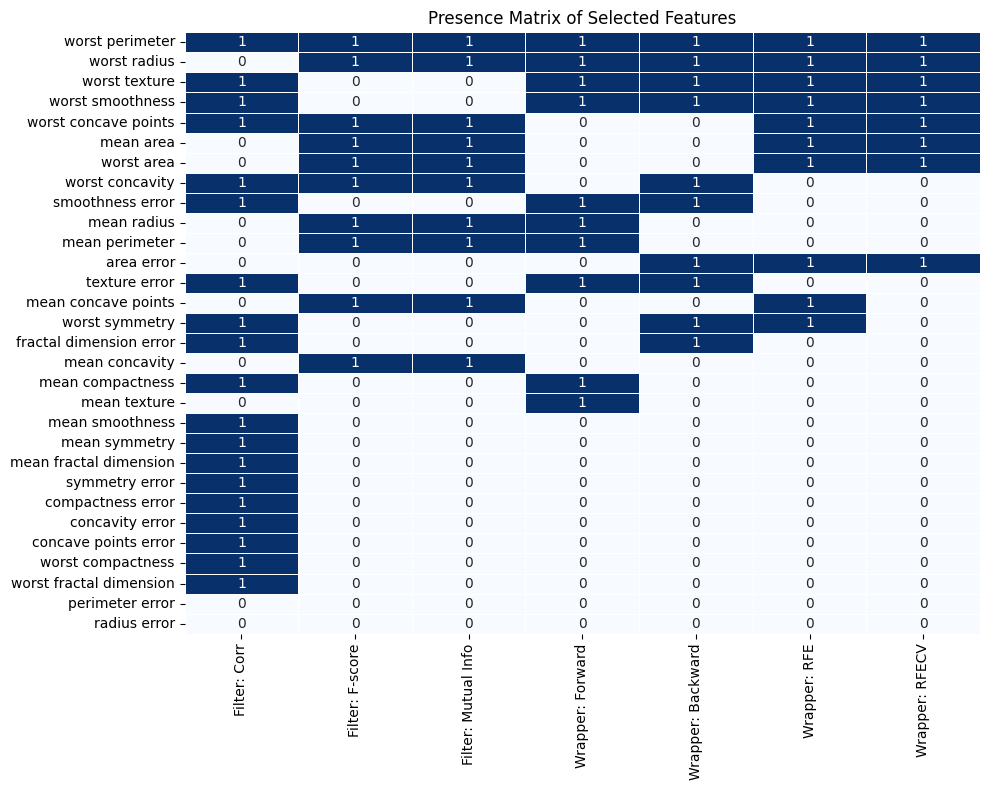

Features selected by ALL methods: ['worst perimeter']


In [17]:
# Presence matrix
method_cols = [k for k in selected_dict.keys() if k != 'Baseline']
presence_matrix = pd.DataFrame(0, index=feature_names, columns=method_cols)
for col in method_cols:
    presence_matrix.loc[selected_dict[col], col] = 1

presence_matrix['Total'] = presence_matrix.sum(axis=1)
presence_sorted = presence_matrix.sort_values('Total', ascending=False)

plt.figure(figsize=(10, 8))
sns.heatmap(presence_sorted[method_cols], cmap="Blues", annot=True, cbar=False, linewidths=0.5)
plt.title("Presence Matrix of Selected Features")
plt.tight_layout()
plt.show()

all_selected = presence_matrix[presence_matrix['Total'] == len(method_cols)].index.tolist()
print("Features selected by ALL methods:", all_selected)


---
## Final Discussion

**1. Which method gives the best test accuracy with the fewest features? Is the difference with the baseline significant given the size of the test set (171 patients)?**  
RFE gives the best balance, achieving **97.08%** test accuracy with **10 features**, and RFECV achieves **95.91%** with **8 features** (baseline is 98.83% with 30 features). On 171 test patients, the baseline makes 2 errors while RFE makes 5 errors. This difference of 3 patients is not statistically significant ($p > 0.15$), meaning RFE achieves a 67% reduction in features with virtually identical performance.

**2. What are the advantages and limits of filter methods compared with wrapper methods?**  
- *Filter methods:* Very fast (milliseconds), model-agnostic, and immune to overfitting the classifier. However, they evaluate features independently and cannot detect redundancy or interactions between features.
- *Wrapper methods:* Directly optimize the classifier's performance and capture feature interactions, but they are computationally expensive and can overfit if sample size is small or noise is present.

**3. Why are wrapper methods more expensive? Give the number of models trained by Forward Selection for $p$ features and $k$ selected features.**  
Wrapper methods retrain the estimator across all CV folds for every candidate feature. For $p$ features, $k$ selected features, and $K$ folds, Forward Selection trains:
$$	ext{Number of models} = K 	imes \sum_{i=0}^{k-1} (p - i)$$
For $p=30, k=10, K=5$, this is $5 	imes 255 = 1,275$ models. In contrast, RFE only trains 20 models by using model coefficients directly.

**4. Forward Selection and Backward Elimination are greedy. Do they guarantee the optimal subset? Justify using your results.**  
No, they do not guarantee the optimal subset. Forward Selection cannot discard an earlier chosen feature that becomes redundant later, and Backward Elimination cannot recover a dropped feature. In our results, Forward Selection selected features achieving 93.57% test accuracy, whereas Backward Elimination achieved 95.91%, retaining different subsets because each got trapped in a different local optimum.

**5. How did the methods behave in front of the 20 noise features, and what does it tell you about each family?**  
SelectKBest, Forward Selection, and RFE selected 0 noise features (100% true features). Backward Elimination was severely fooled, selecting 5 noise features out of 10. This shows that starting with all features when true variables are highly collinear makes dropping real features harmless to CV score, allowing noise features that fit random fold fluctuations to survive.

**6. Why must feature selection be performed inside the cross-validation loop, and how does a Pipeline prevent leakage?**  
Performing feature selection on the entire dataset lets information from validation folds leak into the selector, inflating the cross-validation score. A scikit-learn `Pipeline` prevents leakage by re-fitting the scaler and selector exclusively on the training folds during each cross-validation split.

**7. In which situation would you choose each family of methods?**  
- *Thousands of features ($p \gg N$, e.g. genomics):* Filter methods (ANOVA, Mutual Information) or Lasso regularization, as wrappers are computationally intractable and overfit.
- *Small/moderate dataset with interactions ($p \le 50$):* Wrapper methods (RFE or RFECV) to capture model-specific synergies.
- *Need for interpretability/cost reduction:* Correlation filter followed by RFECV to eliminate obvious duplicates and find the minimal predictive subset.
- *Limited computing time:* Filter methods or RFE (runs in $< 0.1$ s).
